# 02 — Model comparison (M2)

Candidate classifier: one row per *(GPS observation, candidate arc)*, target = 1 if the candidate is the ground-truth arc. This notebook only **reads saved outputs** of `scripts/train_models.py`, `scripts/summarize_metrics.py` and `scripts/plot_models.py` — every number here is in a CSV under `results/m2/`.

Reproduce:
```
python scripts/build_dataset.py --split train
python scripts/build_dataset.py --split student_test
python scripts/train_models.py --models all --obs-every 4 --tag v1
python scripts/summarize_metrics.py --tag v1
python scripts/plot_models.py --tag v1 --chosen lgbm
```

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R = ROOT / "results" / "m2"
P = R / "plots"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)
def show(name, width=900):
    display(Image(filename=str(P / name), width=width))

## 1. Setup of the v1 run
Labels: M3's order-preserving route alignment. Training rows: every 4th GPS point per trip (all its candidates). CV: GroupKFold(5) by `trip_id`. student_test = 10 development trips.

In [2]:
comp = pd.read_csv(R / "model_comparison_v1.csv")
comp[["model", "family", "key_config", "n_train_rows", "n_folds", "obs_every", "label_source"]]

,model,family,key_config,n_train_rows,n_folds,obs_every,label_source
0,lgbm,boosting (LightGBM),n_estimators=500; learning_rate=0.05; num_leav...,516188,5,4,train=M3_alignment; student_test=M3_alignment
1,xgb,boosting (XGBoost),n_estimators=500; learning_rate=0.05; max_depth=6,516188,5,4,train=M3_alignment; student_test=M3_alignment
2,hgb,boosting (sklearn hist),learning_rate=0.05; max_leaf_nodes=31; max_ite...,516188,5,4,train=M3_alignment; student_test=M3_alignment
3,logreg,linear / probabilistic,C=1.0; class_weight=balanced; max_iter=1000,516188,5,4,train=M3_alignment; student_test=M3_alignment
4,gnb,probabilistic (naive Bayes),var_smoothing=1e-09,516188,5,4,train=M3_alignment; student_test=M3_alignment
5,mlp,neural network,"hidden_layer_sizes=(64, 32); activation=relu; ...",516188,5,4,train=M3_alignment; student_test=M3_alignment
6,et,ensemble (randomised trees),n_estimators=300; max_depth=None; min_samples_...,500318,5,4,train=M3_alignment; student_test=M3_alignment
7,rf,ensemble (bagging),n_estimators=300; max_depth=None; min_samples_...,500318,5,4,train=M3_alignment; student_test=M3_alignment
8,knn,instance-based,n_neighbors=25; weights=distance,100379,5,4,train=M3_alignment; student_test=M3_alignment


## 2. Cross-validation metrics (mean ± std over 5 folds)

In [3]:
ms = pd.read_csv(R / "metrics_summary_v1.csv")
cv_cols = ["accuracy", "precision", "recall", "f1", "macro_f1", "logloss", "top1"]
cv = pd.DataFrame({"model": ms["model"]})
for k in cv_cols:
    cv[k] = ms[f"cv_{k}_mean"].map("{:.4f}".format) + " ± " + ms[f"cv_{k}_std"].map("{:.4f}".format)
cv

,model,accuracy,precision,recall,f1,macro_f1,logloss,top1
0,hgb,0.9838 ± 0.0028,0.9139 ± 0.0202,0.8971 ± 0.0209,0.9054 ± 0.0187,0.9483 ± 0.0101,0.0410 ± 0.0082,0.9138 ± 0.0180
1,lgbm,0.9840 ± 0.0031,0.9158 ± 0.0233,0.8962 ± 0.0198,0.9058 ± 0.0204,0.9485 ± 0.0110,0.0407 ± 0.0081,0.9137 ± 0.0194
2,rf,0.9838 ± 0.0030,0.9301 ± 0.0181,0.8779 ± 0.0252,0.9032 ± 0.0211,0.9472 ± 0.0113,0.0419 ± 0.0076,0.9136 ± 0.0201
3,xgb,0.9836 ± 0.0028,0.9142 ± 0.0238,0.8937 ± 0.0162,0.9038 ± 0.0188,0.9474 ± 0.0102,0.0412 ± 0.0078,0.9130 ± 0.0197
4,mlp,0.9821 ± 0.0026,0.9051 ± 0.0261,0.8865 ± 0.0250,0.8953 ± 0.0182,0.9428 ± 0.0098,0.0511 ± 0.0100,0.9095 ± 0.0185
5,et,0.9828 ± 0.0031,0.9352 ± 0.0187,0.8601 ± 0.0268,0.8960 ± 0.0221,0.9433 ± 0.0118,0.0468 ± 0.0065,0.9058 ± 0.0209
6,logreg,0.9446 ± 0.0057,0.6150 ± 0.0383,0.9658 ± 0.0114,0.7509 ± 0.0296,0.8599 ± 0.0164,0.1316 ± 0.0145,0.8984 ± 0.0216
7,gnb,0.8799 ± 0.0128,0.4180 ± 0.0394,0.9603 ± 0.0134,0.5814 ± 0.0371,0.7556 ± 0.0222,0.9920 ± 0.0864,0.8647 ± 0.0199
8,knn,0.9705 ± 0.0025,0.8913 ± 0.0162,0.7504 ± 0.0226,0.8147 ± 0.0190,0.8993 ± 0.0101,0.1011 ± 0.0155,0.8545 ± 0.0207


## 3. student_test metrics
Pair metrics at threshold 0.5 on `label_valid` rows; ROC-AUC / PR-AUC are threshold-free. Top-1 = share of valid GPS points whose highest-probability candidate is the ground-truth arc (pooled over points).

In [4]:
ms[["model", "st_accuracy", "st_precision", "st_recall", "st_f1", "st_macro_f1", "st_logloss",
    "st_roc_auc", "st_pr_auc", "st_top1", "st_undirected_top1"]]

,model,st_accuracy,st_precision,st_recall,st_f1,st_macro_f1,st_logloss,st_roc_auc,st_pr_auc,st_top1,st_undirected_top1
0,hgb,0.9852,0.9104,0.9033,0.9069,0.9494,0.0374,0.9967,0.9691,0.9185,0.9518
1,lgbm,0.9852,0.9115,0.9022,0.9068,0.9494,0.0373,0.9967,0.9701,0.9162,0.9515
2,rf,0.9843,0.9248,0.8745,0.8990,0.9452,0.0399,0.9963,0.9670,0.9089,0.9487
3,xgb,0.9853,0.9126,0.9020,0.9073,0.9496,0.0375,0.9967,0.9696,0.9158,0.9509
4,mlp,0.9823,0.8946,0.8819,0.8882,0.9393,0.0459,0.9953,0.9574,0.9005,0.9459
5,et,0.9823,0.9279,0.8444,0.8842,0.9373,0.0451,0.9958,0.9625,0.8980,0.9395
6,logreg,0.9392,0.5698,0.9712,0.7182,0.8421,0.1405,0.9909,0.9179,0.8759,0.9253
7,gnb,0.8776,0.3926,0.9756,0.5599,0.7444,1.2357,0.9715,0.6382,0.8412,0.9206
8,knn,0.9703,0.8667,0.7423,0.7997,0.8918,0.0999,0.9801,0.8790,0.8511,0.8919


### Accuracy baseline
Share of student_test rows that are negatives = accuracy of always predicting 0.

In [5]:
r = ms.iloc[0]
neg, pos = r.st_tn + r.st_fp, r.st_tp + r.st_fn
print(f"rows={int(neg + pos):,}  positives={int(pos):,}  all-zeros accuracy={neg / (neg + pos):.4f}")

rows=238,260  positives=19,012  all-zeros accuracy=0.9202


## 4. Confusion counts, route continuity, speed

In [6]:
ms[["model", "st_tp", "st_fp", "st_fn", "st_tn", "route_continuity", "route_breaks",
    "train_time_s", "infer_ms_per_1k", "n_train_rows"]]

,model,st_tp,st_fp,st_fn,st_tn,route_continuity,route_breaks,train_time_s,infer_ms_per_1k,n_train_rows
0,hgb,17174,1690,1838,217558,0.7927,797,15.3362,4.3443,516188
1,lgbm,17152,1665,1860,217583,0.7926,793,4.9629,1.7252,516188
2,rf,16626,1351,2386,217897,0.7885,862,70.8557,1.8772,500318
3,xgb,17149,1642,1863,217606,0.7953,783,6.0195,0.8330,516188
4,mlp,16766,1976,2246,217272,0.7669,928,255.3543,1.5139,516188
5,et,16054,1248,2958,218000,0.7353,1185,28.6642,5.6348,500318
6,logreg,18464,13938,548,205310,0.7153,1178,2.9941,0.0897,516188
7,gnb,18549,28703,463,190545,0.6917,1553,0.1602,0.3111,516188
8,knn,14113,2170,4899,217078,0.6416,1807,0.0282,45.4491,100379


## 5. Per-fold Top-1 and head-to-head against LightGBM

In [7]:
folds = pd.read_csv(R / "cv_folds_v1.csv")
pivot = folds.pivot(index="model", columns="fold", values="val_top1")
display(pivot.loc[ms["model"]])
rows = []
for m in pivot.index.drop("lgbm"):
    d = pivot.loc["lgbm"] - pivot.loc[m]
    rows.append({"vs": m, "mean diff (lgbm - m)": d.mean(), "lgbm wins (of 5 folds)": int((d > 0).sum())})
pd.DataFrame(rows).sort_values("mean diff (lgbm - m)")

fold,0,1,2,3,4
model,,,,,
hgb,0.8826,0.9308,0.9303,0.9066,0.9186
lgbm,0.8795,0.9332,0.9296,0.9065,0.9195
rf,0.8808,0.9343,0.9320,0.9019,0.9193
xgb,0.8788,0.9335,0.9305,0.9064,0.9156
mlp,0.8802,0.9299,0.9242,0.8964,0.9167
et,0.8738,0.9292,0.9240,0.8903,0.9118
logreg,0.8658,0.9231,0.9153,0.8808,0.9068
gnb,0.8415,0.8615,0.8959,0.8475,0.8772
knn,0.8263,0.8750,0.8768,0.8343,0.8601


,vs,mean diff (lgbm - m),lgbm wins (of 5 folds)
2,hgb,-0.0001,2
6,rf,0.0000,2
7,xgb,0.0007,3
5,mlp,0.0042,4
0,et,0.0078,5
4,logreg,0.0153,5
1,gnb,0.0490,5
3,knn,0.0592,5


## 6. Over-fitting check: train-fold Top-1 vs CV Top-1

In [8]:
of = ms[["model", "cv_train_top1_mean", "cv_top1_mean"]].copy()
of["gap"] = of["cv_train_top1_mean"] - of["cv_top1_mean"]
of

,model,cv_train_top1_mean,cv_top1_mean,gap
0,hgb,0.9583,0.9138,0.0445
1,lgbm,0.9431,0.9137,0.0294
2,rf,0.9705,0.9136,0.0568
3,xgb,0.9419,0.9130,0.0289
4,mlp,0.9353,0.9095,0.0258
5,et,0.9491,0.9058,0.0432
6,logreg,0.8989,0.8984,0.0006
7,gnb,0.8653,0.8647,0.0006
8,knn,1.0000,0.8545,0.1455


## 7. Plots (generated from the CSVs by `scripts/plot_models.py`)

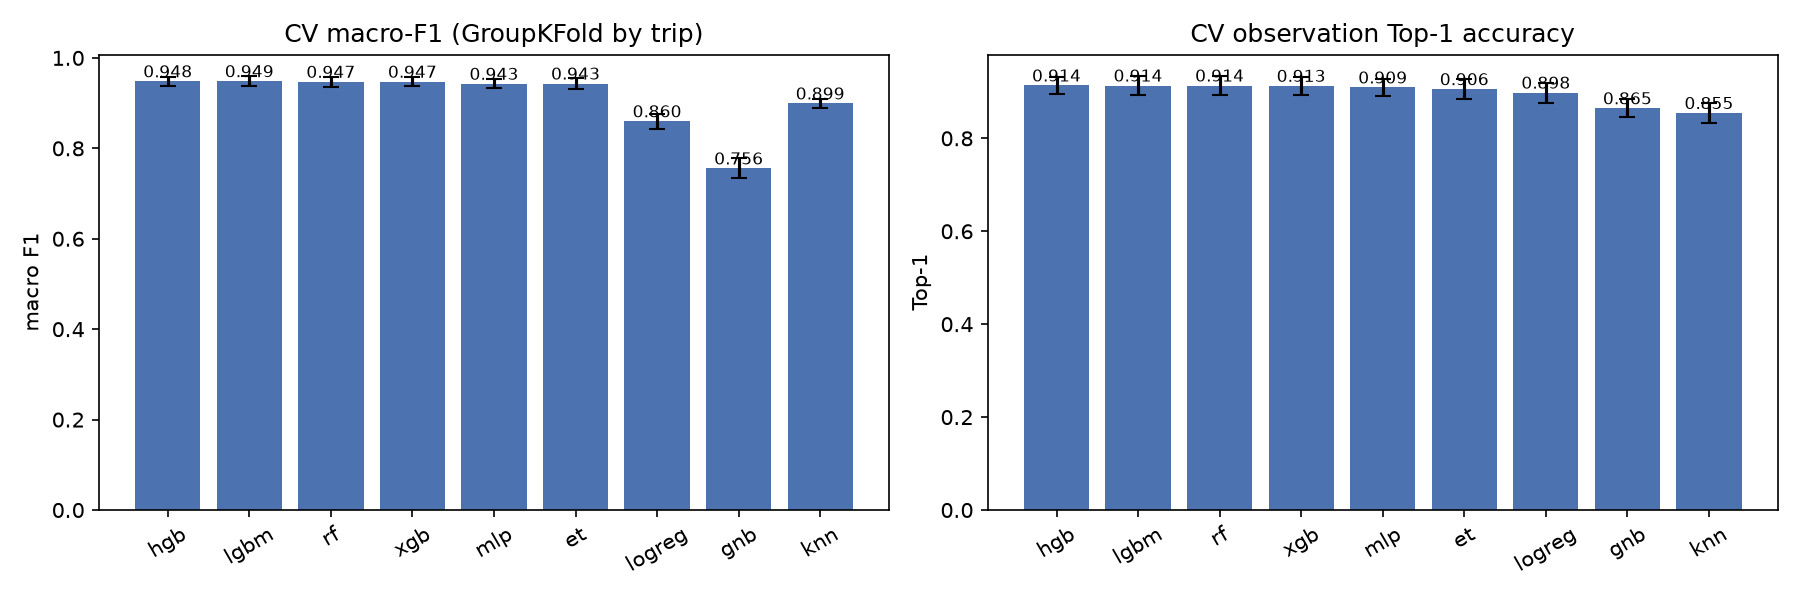

In [9]:
show("cv_scores_v1.png", 1000)

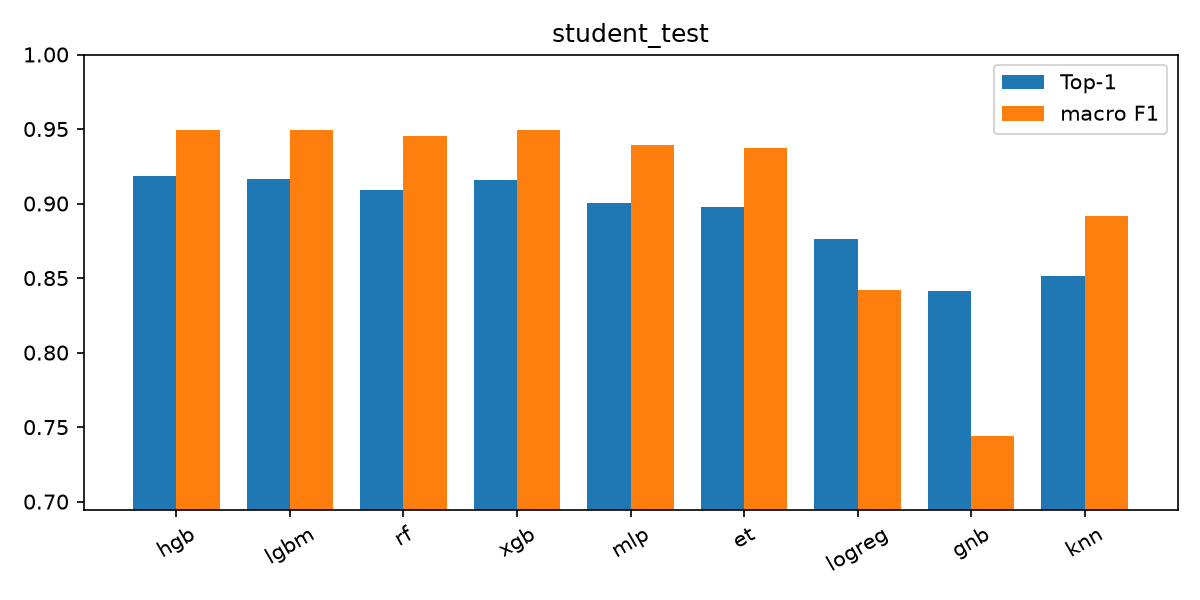

In [10]:
show("student_test_scores_v1.png", 700)

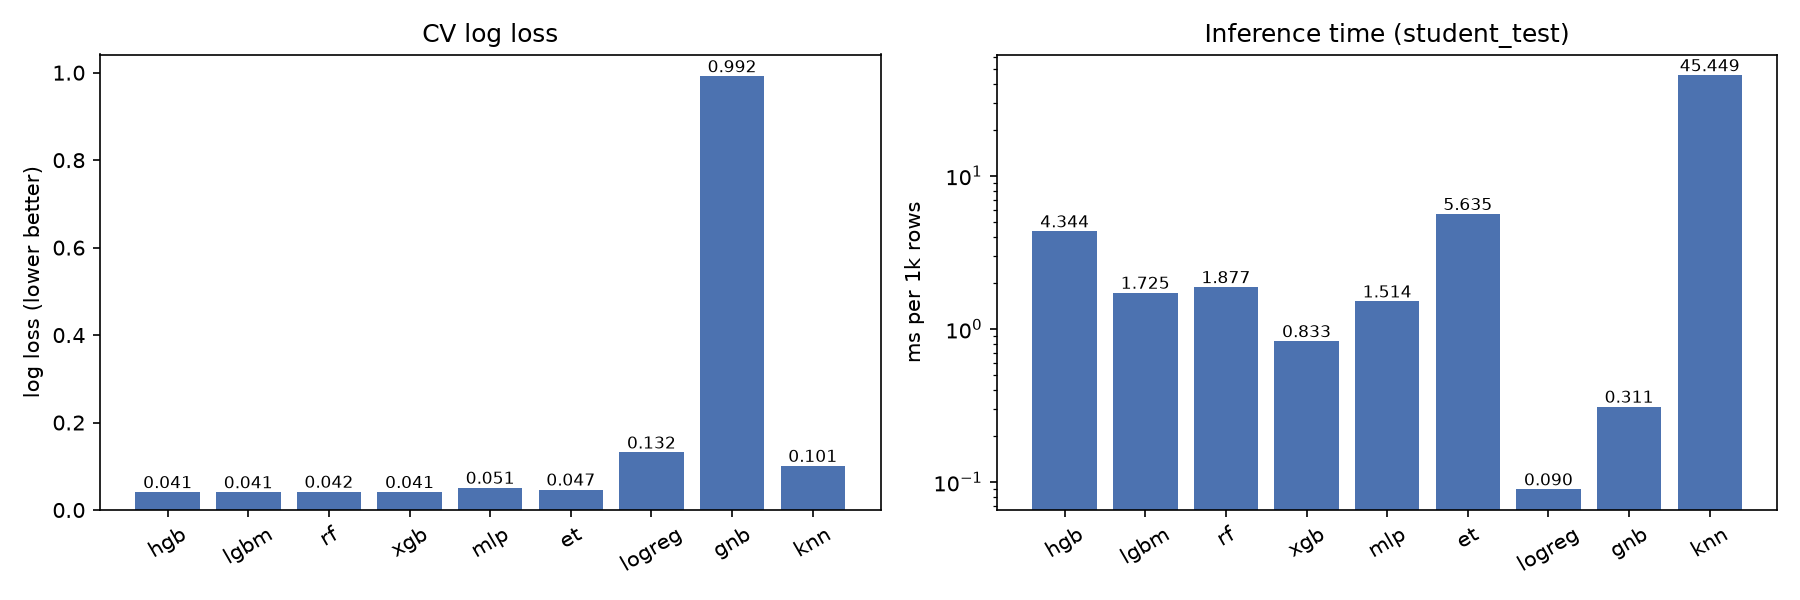

In [11]:
show("logloss_infer_v1.png", 1000)

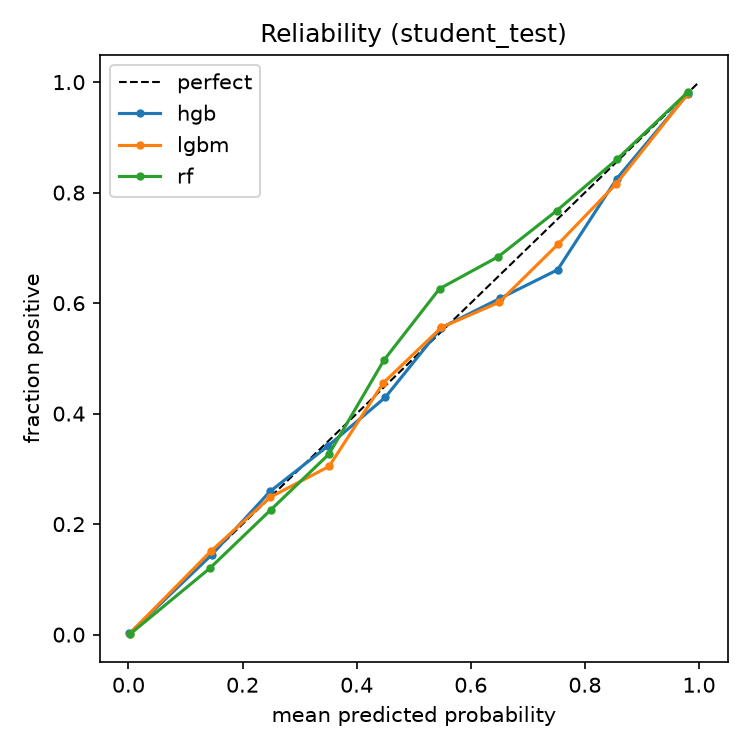

In [12]:
show("reliability_v1.png", 450)

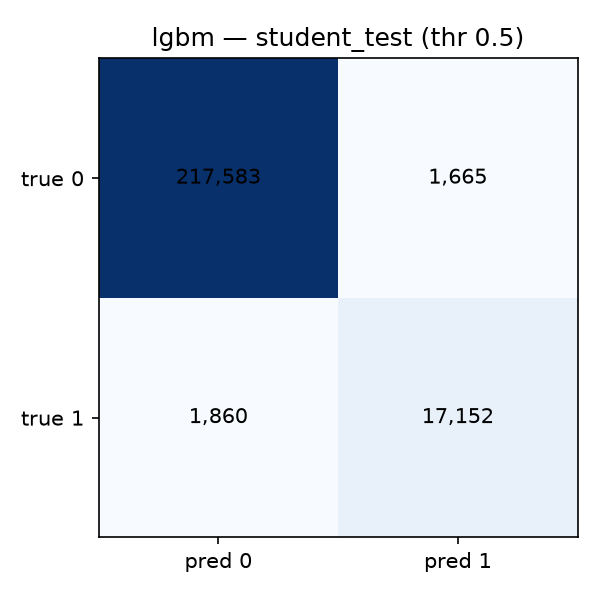

In [13]:
show("confusion_lgbm_v1.png", 350)

### Training histories (real per-iteration logs only: boosting + MLP)

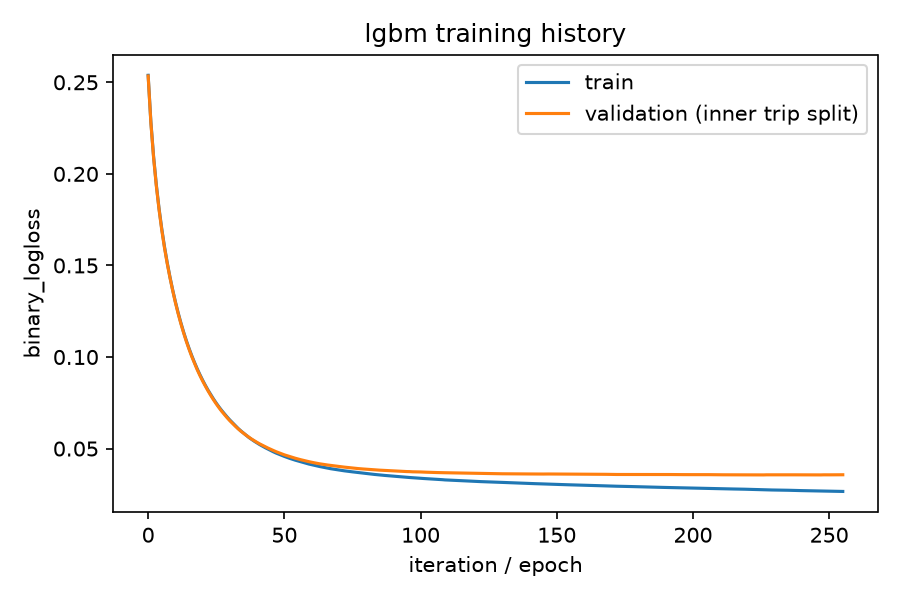

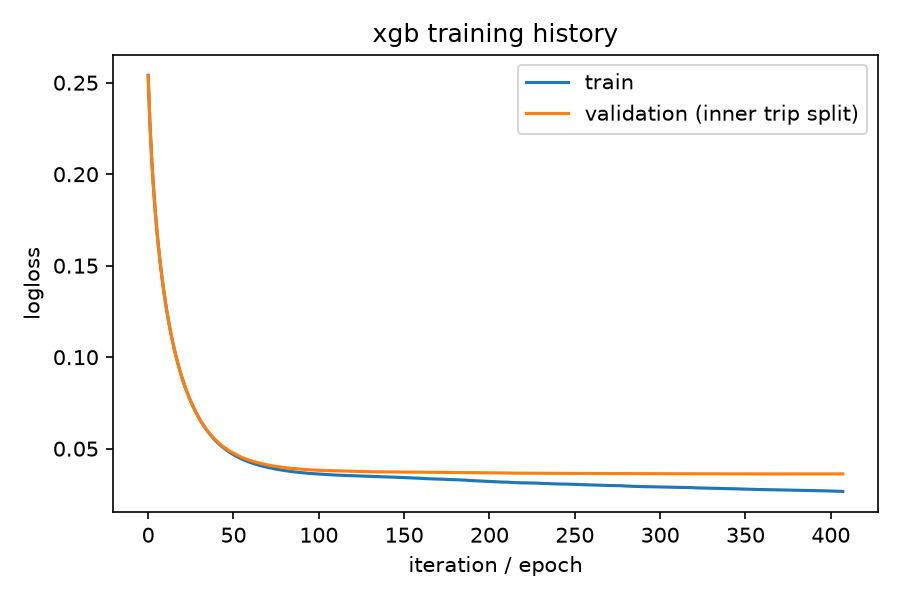

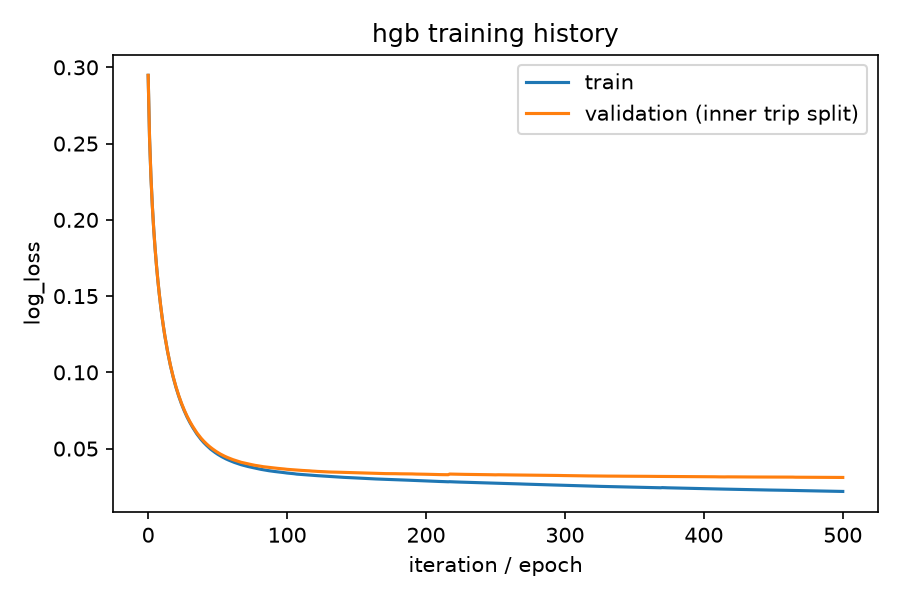

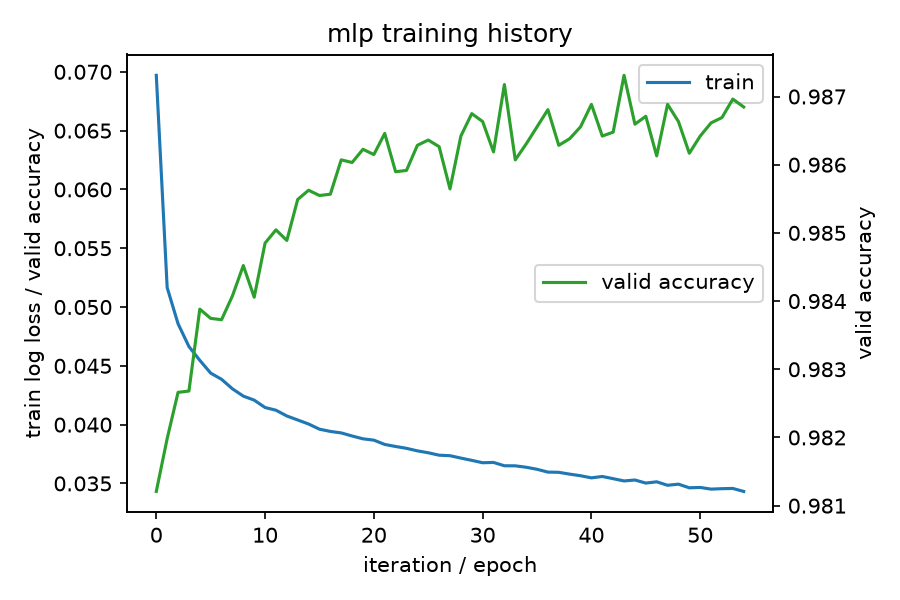

In [14]:
for m in ["lgbm", "xgb", "hgb", "mlp"]:
    if (P / f"history_{m}_v1.png").exists():
        show(f"history_{m}_v1.png", 520)

## 8. Effect of the labels: v0 (fallback nearest-route-arc) vs v1 (M3 alignment)

In [15]:
v0 = pd.read_csv(R / "model_comparison_v0.csv")[["model", "cv_top1_mean", "st_top1"]]
v1 = comp[["model", "cv_top1_mean", "st_top1"]]
lab = v0.merge(v1, on="model", suffixes=("_v0", "_v1"))
lab["cv_top1_change"] = lab["cv_top1_mean_v1"] - lab["cv_top1_mean_v0"]
lab.sort_values("cv_top1_mean_v1", ascending=False)

,model,cv_top1_mean_v0,st_top1_v0,cv_top1_mean_v1,st_top1_v1,cv_top1_change
2,hgb,0.8974,0.8886,0.9138,0.9185,0.0164
0,lgbm,0.9000,0.8850,0.9137,0.9162,0.0137
7,rf,0.8955,0.8807,0.9136,0.9089,0.0182
1,xgb,0.8978,0.8807,0.9130,0.9158,0.0152
5,mlp,0.8958,0.8734,0.9095,0.9005,0.0137
6,et,0.8927,0.8750,0.9058,0.8980,0.0131
3,logreg,0.8844,0.8526,0.8984,0.8759,0.0140
4,gnb,0.8254,0.7964,0.8647,0.8412,0.0393
8,knn,0.8447,0.8277,0.8545,0.8511,0.0098


## 9. Feature importance of the exported (tuned) LightGBM
Permutation importance = drop in student_test Top-1 when one feature column is shuffled (3 repeats); gain = total split gain in LightGBM.

,feature,perm_top1_drop_mean,perm_top1_drop_std,gain_or_impurity
0,win5_heading_cos,0.2988,0.0034,2540745.3878
1,win5_rel,0.0390,0.0016,923089.5503
2,proj_frac,0.0376,0.0018,361191.4198
3,dist_m,0.0245,0.0002,58280.6234
4,dist_minus_min,0.0112,0.0003,5201227.1070
5,to_deg,0.0075,0.0004,72595.9515
6,dist_to_end_m,0.0034,0.0002,141414.1792
7,heading_cos,0.0030,0.0005,756573.1532
8,has_twin,0.0023,0.0005,87797.9912
9,win5_mean_dist,0.0017,0.0006,106831.1598


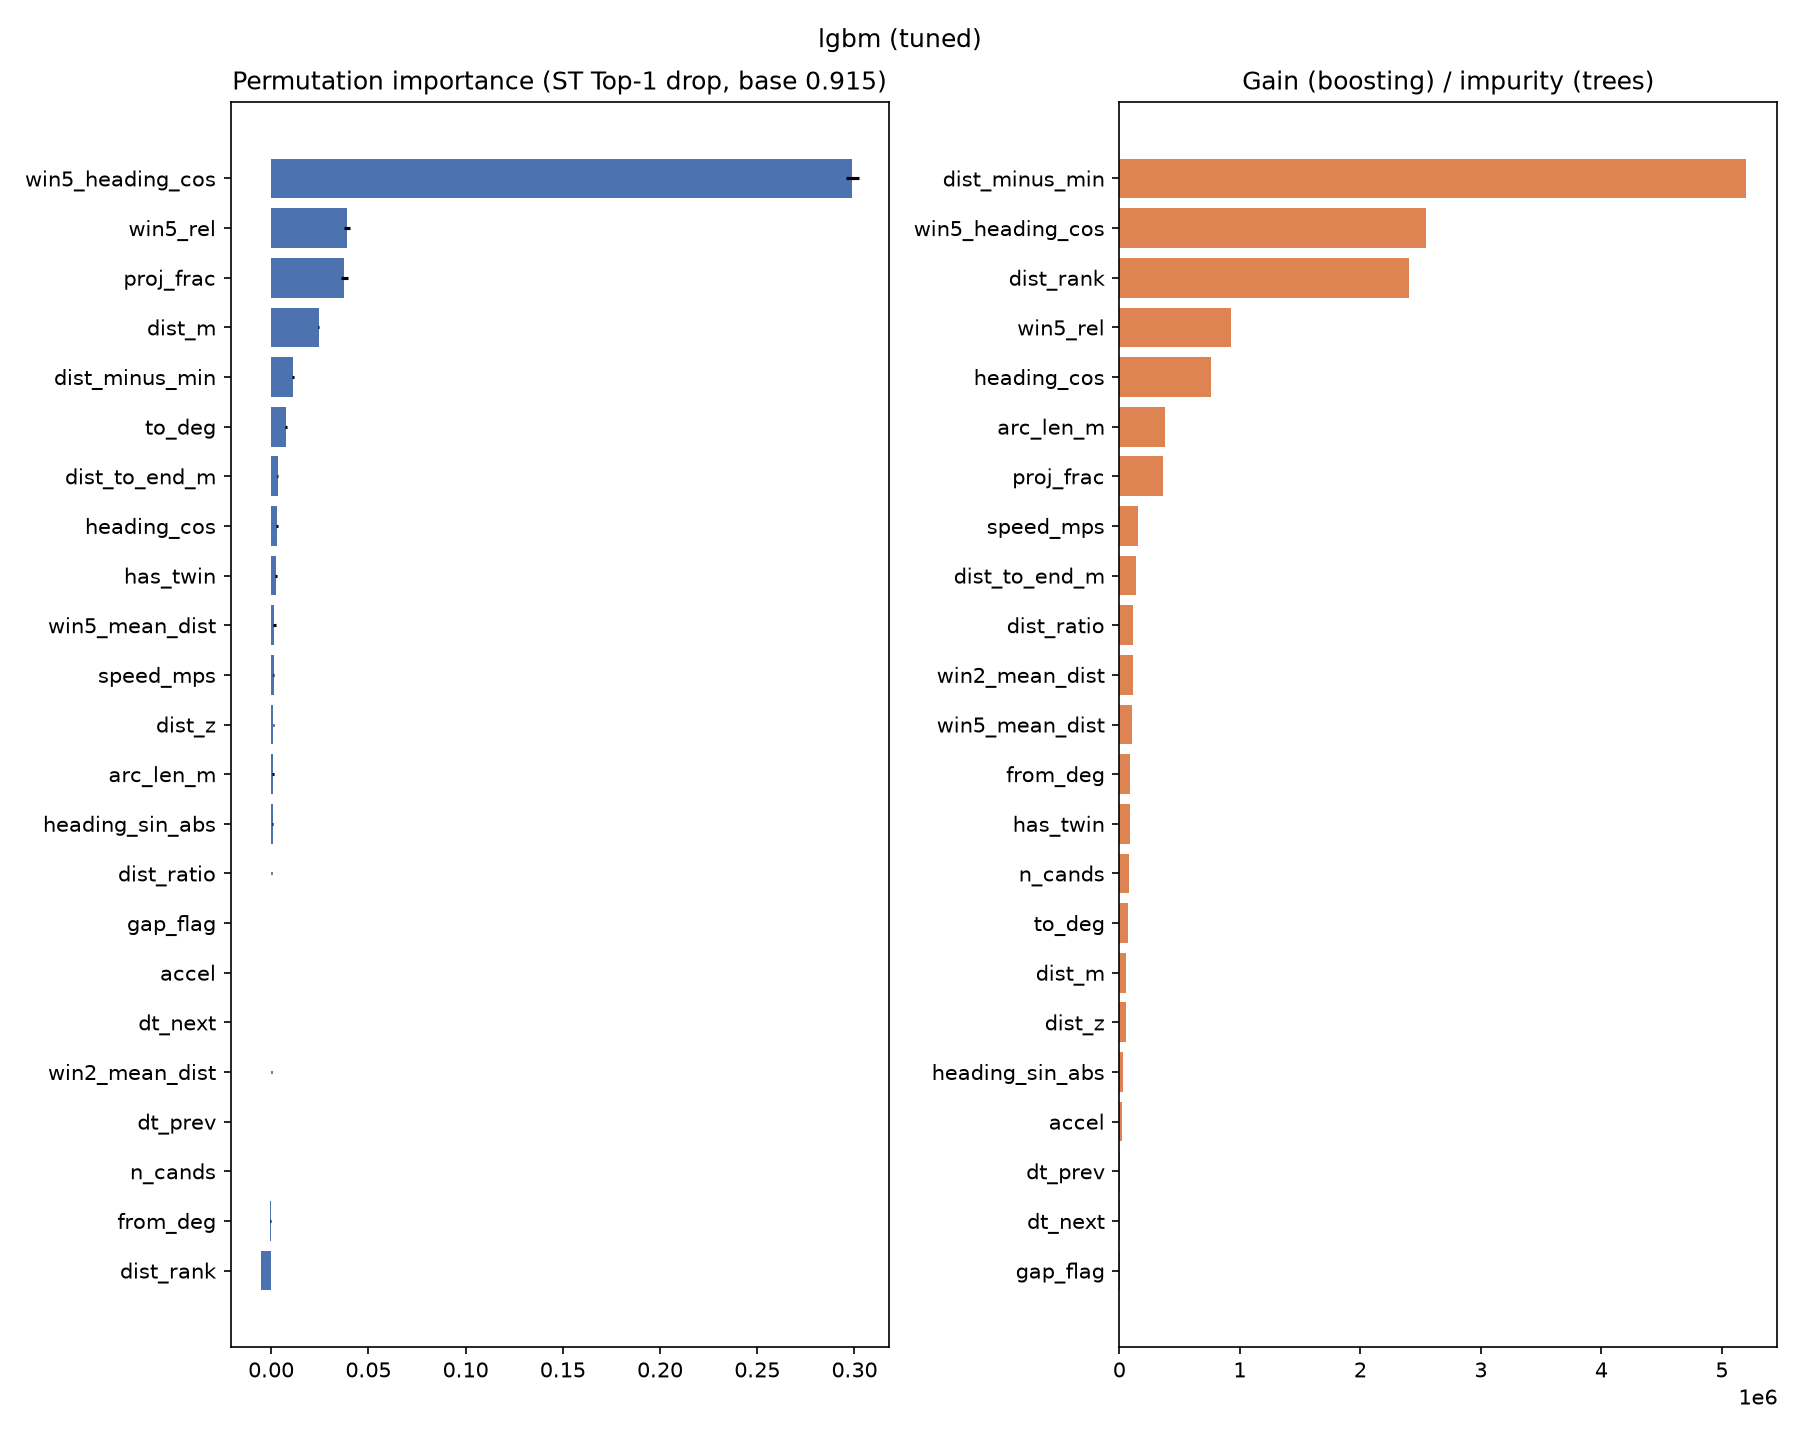

In [16]:
fi = pd.read_csv(R / "feature_importance_tuned.csv")
display(fi)
show("feature_importance_tuned.png", 1000)